In [1]:
# ===== TASK 1: Imports =====
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

In [2]:
# ===== TASK 1: Load data and inspect class balance / invalid values =====
df = pd.read_csv("diabetes.csv")
print("Shape:", df.shape)
print("Class balance:\n", df.Outcome.value_counts(), "\n", df.Outcome.value_counts(normalize=True).round(3))
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("\nZeros (invalid) per column:\n", (df[cols] == 0).sum())
print("NaNs:", df.isna().sum().sum())

Shape: (768, 9)
Class balance:
 Outcome
0    500
1    268
Name: count, dtype: int64 
 Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64

Zeros (invalid) per column:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64
NaNs: 0


In [3]:
# ===== TASK 1: Treat zeros as missing, choose exactly two predictors =====
df[cols] = df[cols].replace(0, np.nan)
feats = ["Glucose", "BMI"]
X = df[feats].values
y = df.Outcome.values

# ===== TASK 1: Stratified 80/20 split, random_state=42 =====
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# ===== TASK 1: Impute using TRAINING-only medians =====
med = np.nanmedian(Xtr, axis=0)
for j in range(2):
    Xtr[np.isnan(Xtr[:, j]), j] = med[j]
    Xte[np.isnan(Xte[:, j]), j] = med[j]

# ===== TASK 1: Standardize using TRAINING-only mean/std =====
mu, sd = Xtr.mean(0), Xtr.std(0)
Xtr_s, Xte_s = (Xtr - mu) / sd, (Xte - mu) / sd

print("Train/test shapes:", Xtr.shape, Xte.shape)
print("Positive rate  train: %.3f  test: %.3f" % (ytr.mean(), yte.mean()))
print("Train medians:", med, "| mean:", mu.round(2), "| std:", sd.round(2))

Train/test shapes: (614, 2) (154, 2)
Positive rate  train: 0.349  test: 0.351
Train medians: [117.   32.4] | mean: [121.67  32.45] | std: [29.98  6.82]


In [4]:
# ===== TASK 2: Helper - sigmoid =====
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

# ===== TASK 2: Scratch Perceptron (step activation, mistake-driven updates, bias update) =====
def perceptron_fit(X, y, lr=0.1, epochs=200, seed=42):
    rng = np.random.default_rng(seed)
    w = np.zeros(X.shape[1]); b = 0.0
    for ep in range(epochs):                       # fixed iteration count
        errors = 0
        for i in rng.permutation(len(y)):
            pred = int(X[i] @ w + b >= 0)          # step activation
            change = lr * (y[i] - pred)
            w += change * X[i]; b += change        # weight + bias update
            errors += int(pred != y[i])
        if errors == 0:                            # stopping rule (only if separable)
            break
    return w, b, ep + 1

# ===== TASK 2: Scratch Logistic Regression (sigmoid + batch gradient descent) =====
def logreg_fit(X, y, lr=0.1, epochs=2000):
    w = np.zeros(X.shape[1]); b = 0.0; losses = []
    for _ in range(epochs):                        # fixed iteration count
        p = sigmoid(X @ w + b)
        w -= lr * (X.T @ (p - y) / len(y))         # dw = X^T (p - y) / m
        b -= lr * np.mean(p - y)                   # db = mean(p - y)
        pc = np.clip(p, 1e-12, 1 - 1e-12)          # clipped for stable log loss
        losses.append(-np.mean(y * np.log(pc) + (1 - y) * np.log(1 - pc)))
    return w, b, losses

In [5]:
# ===== TASK 2: Train scratch models and print coefficients, first 5 predictions, first 5 probabilities =====
pw, pb, pep = perceptron_fit(Xtr_s, ytr)
lw, lb, losses = logreg_fit(Xtr_s, ytr)

p_pred = (Xte_s @ pw + pb >= 0).astype(int)
l_prob = sigmoid(Xte_s @ lw + lb)
l_pred = (l_prob >= 0.5).astype(int)

print("[Scratch Perceptron] w =", pw.round(4), " b = %.4f" % pb, " epochs run =", pep)
print("  First 5 test predictions:", p_pred[:5].tolist())
print("\n[Scratch LogReg] w =", lw.round(4), " b = %.4f" % lb, " final loss = %.4f" % losses[-1])
print("  First 5 test predictions:", l_pred[:5].tolist())
print("  First 5 P(class=1):", l_prob[:5].round(4).tolist())

[Scratch Perceptron] w = [0.0945 0.0953]  b = -0.2000  epochs run = 200
  First 5 test predictions: [0, 0, 0, 0, 0]

[Scratch LogReg] w = [1.2496 0.6663]  b = -0.8380  final loss = 0.4727
  First 5 test predictions: [1, 0, 0, 0, 0]
  First 5 P(class=1): [0.5559, 0.0586, 0.3806, 0.161, 0.0557]


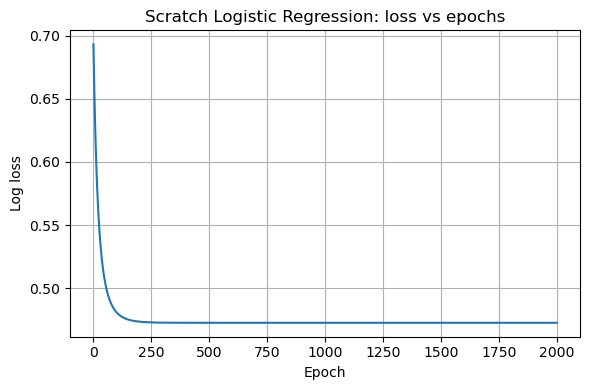

In [6]:
# ===== TASK 2: Plot loss vs epochs for scratch logistic regression =====
plt.figure(figsize=(6, 4))
plt.plot(losses)
plt.xlabel("Epoch"); plt.ylabel("Log loss")
plt.title("Scratch Logistic Regression: loss vs epochs")
plt.grid(True); plt.tight_layout(); plt.show()

In [7]:
# ===== TASK 3: sklearn models on the SAME prepared data, random_state=42 =====
sp = Perceptron(max_iter=1000, tol=1e-3, random_state=42).fit(Xtr_s, ytr)
sl = LogisticRegression(random_state=42).fit(Xtr_s, ytr)
sp_pred, sl_pred = sp.predict(Xte_s), sl.predict(Xte_s)

print("[sklearn Perceptron] w =", sp.coef_[0].round(4), " b = %.4f" % sp.intercept_[0])
print("[sklearn LogReg]     w =", sl.coef_[0].round(4), " b = %.4f" % sl.intercept_[0])

[sklearn Perceptron] w = [ 2.0347 -2.6839]  b = 0.0000
[sklearn LogReg]     w = [1.2311 0.6572]  b = -0.8336


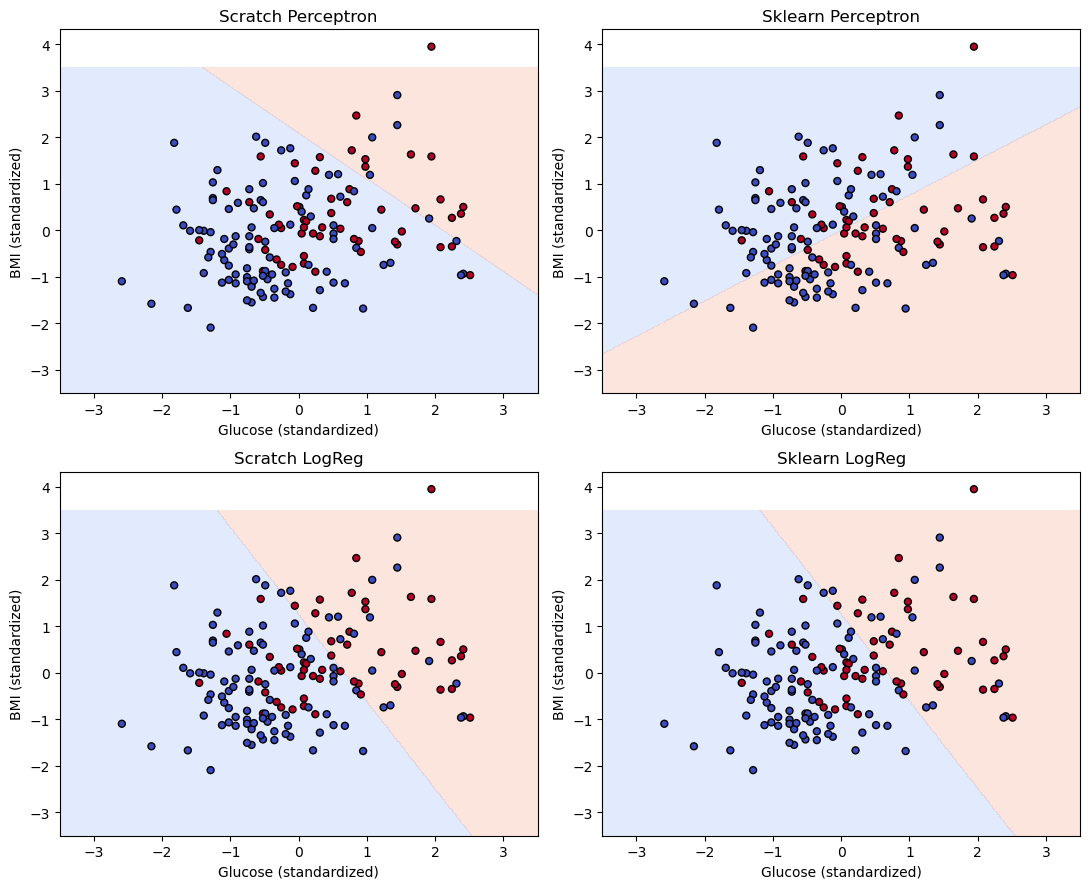

In [8]:
# ===== TASK 3: Plot all four decision boundaries =====
models = {
    "Scratch Perceptron": (pw, pb, p_pred),
    "Sklearn Perceptron": (sp.coef_[0], sp.intercept_[0], sp_pred),
    "Scratch LogReg":     (lw, lb, l_pred),
    "Sklearn LogReg":     (sl.coef_[0], sl.intercept_[0], sl_pred),
}
g1, g2 = np.meshgrid(np.linspace(-3.5, 3.5, 300), np.linspace(-3.5, 3.5, 300))
grid = np.c_[g1.ravel(), g2.ravel()]

fig, ax = plt.subplots(2, 2, figsize=(11, 9))
for a, (name, (w, b, _)) in zip(ax.ravel(), models.items()):
    Z = (grid @ w + b >= 0).reshape(g1.shape)
    a.contourf(g1, g2, Z, alpha=0.25, cmap="coolwarm")
    a.scatter(Xte_s[:, 0], Xte_s[:, 1], c=yte, cmap="coolwarm", edgecolor="k", s=25)
    a.set_title(name); a.set_xlabel("Glucose (standardized)"); a.set_ylabel("BMI (standardized)")
plt.tight_layout(); plt.show()

In [9]:
# ===== TASK 4: Manual metrics (implemented for Scratch LogReg) and verification vs scikit-learn =====
def manual_metrics(yt, yp):
    tp = int(((yt == 1) & (yp == 1)).sum()); tn = int(((yt == 0) & (yp == 0)).sum())
    fp = int(((yt == 0) & (yp == 1)).sum()); fn = int(((yt == 1) & (yp == 0)).sum())
    acc = (tp + tn) / len(yt)
    prec = tp / (tp + fp) if tp + fp else 0
    rec = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0
    return np.array([[tn, fp], [fn, tp]]), acc, prec, rec, f1

cm, a, p, r, f = manual_metrics(yte, l_pred)
print("Manual  (Scratch LogReg): acc=%.4f prec=%.4f rec=%.4f f1=%.4f" % (a, p, r, f))
print("sklearn (Scratch LogReg): acc=%.4f prec=%.4f rec=%.4f f1=%.4f" % (
    accuracy_score(yte, l_pred), precision_score(yte, l_pred), recall_score(yte, l_pred), f1_score(yte, l_pred)))
print("Manual confusion matrix == sklearn:", np.array_equal(cm, confusion_matrix(yte, l_pred)))

Manual  (Scratch LogReg): acc=0.7273 prec=0.6364 rec=0.5185 f1=0.5714
sklearn (Scratch LogReg): acc=0.7273 prec=0.6364 rec=0.5185 f1=0.5714
Manual confusion matrix == sklearn: True


In [10]:
# ===== TASK 4: Confusion matrix + metrics for all four models, compact comparison table =====
rows = []
for name, (_, _, pr) in models.items():
    c = confusion_matrix(yte, pr)
    print(name, "\n", c, "\n")
    rows.append([name, c[0, 0], c[0, 1], c[1, 0], c[1, 1],
                 accuracy_score(yte, pr), precision_score(yte, pr, zero_division=0),
                 recall_score(yte, pr), f1_score(yte, pr)])
table = pd.DataFrame(rows, columns=["Model", "TN", "FP", "FN", "TP", "Accuracy", "Precision", "Recall", "F1"]).round(4)
table

Scratch Perceptron 
 [[95  5]
 [42 12]] 

Sklearn Perceptron 
 [[55 45]
 [26 28]] 

Scratch LogReg 
 [[84 16]
 [26 28]] 

Sklearn LogReg 
 [[84 16]
 [26 28]] 



,Model,TN,FP,FN,TP,Accuracy,Precision,Recall,F1
0,Scratch Perceptron,95,5,42,12,0.6948,0.7059,0.2222,0.3380
1,Sklearn Perceptron,55,45,26,28,0.5390,0.3836,0.5185,0.4409
2,Scratch LogReg,84,16,26,28,0.7273,0.6364,0.5185,0.5714
3,Sklearn LogReg,84,16,26,28,0.7273,0.6364,0.5185,0.5714
